# Giorno 3, mattina: grafici per la pubblicazione

Obiettivo: una figura pronta per la sottomissione, esportata in PDF vettoriale alla
larghezza di colonna della rivista, con font e spessori a norma.

Materiali di oggi, nella cartella `materiali/`:
- `figure_pubblicazione.py`: impostazioni e funzione di export conformi ai requisiti editoriali;
- `personalizzazione_grafici.ipynb`: la **scheda di riferimento**, 33 casi reali (tratteggi,
  tick, annotazioni, legende fuori dagli assi, palette per daltonici, inset, doppio asse…), ognuno
  con la riga di codice che lo risolve. Non va imparata a memoria, basta tenerla aperta accanto agli esercizi.

## 0. Cella di avvio

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

def trova_dati():
    for cand in [Path("../dati"), Path("dati"), Path("corso_python_CNR/dati")]:
        if cand.exists():
            return cand
    for radice in [Path(".."), Path("."), Path("corso_python_CNR")]:
        if (radice / "genera_dati.py").exists():
            sys.path.insert(0, str(radice.resolve()))
            from genera_dati import genera_tutto
            return genera_tutto(radice / "dati")
    raise FileNotFoundError("Cartella 'dati' non trovata: carica la cartella del corso.")

DATI = trova_dati()
MATERIALI = DATI.parent / "materiali"
sys.path.insert(0, str(MATERIALI.resolve()))
from figure_pubblicazione import stile_rivista, stile_rivista_ctx, LARGHEZZE, CM, salva_figura, controlla_font, verifica_figura
print("matplotlib", mpl.__version__, "| materiali:", MATERIALI.resolve())

matplotlib 3.11.1 | materiali: /home/claude/corso_python_cnr/materiali


### I dati di oggi

Tutti da laboratorio (sintetici, ma verosimili): una retta di taratura con repliche, i
voltammogrammi di ieri, una cinetica di degradazione, un confronto fra trattamenti.

In [2]:
tar = pd.read_csv(DATI / "taratura.csv")
cin = pd.read_csv(DATI / "cinetica.csv")
grp = pd.read_csv(DATI / "confronto_gruppi.csv")

def leggi_dpv(percorso):
    meta, E, i = {}, [], []
    for r in percorso.read_text(encoding="utf-8").splitlines():
        if r.startswith("#"):
            k, v = r.split(":", 1); meta[k.strip("# ")] = v.strip()
        elif r and not r.startswith("E("):
            e, c = r.split("\t"); E.append(float(e)); i.append(float(c))
    return meta, np.array(E), np.array(i)

vamm = [leggi_dpv(f) for f in sorted((DATI / "strumento").glob("DPV_S0[3-8].txt"))]
print(tar.head(3), "\n", len(vamm), "voltammogrammi")

   conc_uM  replica   i_uA
0        1        1  0.625
1        1        2  0.383
2        1        3  0.705 
 6 voltammogrammi


---
## 1. Anatomia di una figura (solo l'API a oggetti)

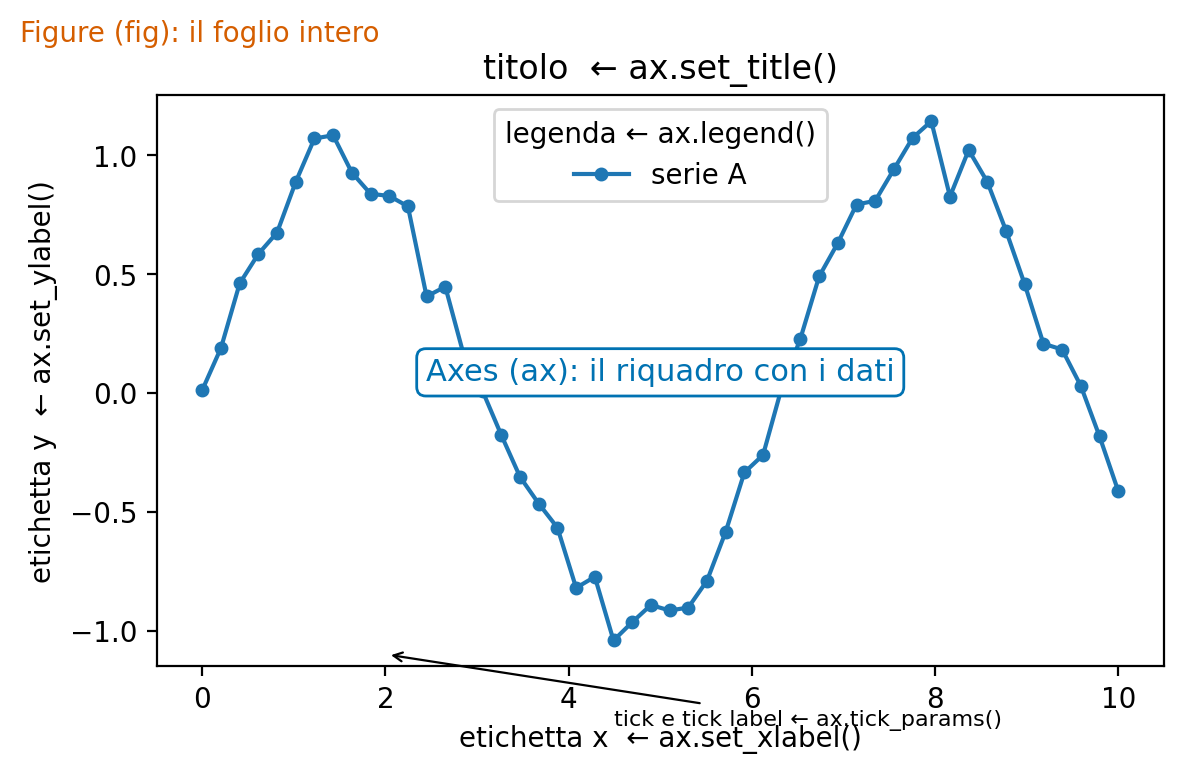

- `Figure` (`fig`): il foglio. Ha dimensioni fisiche (in pollici) e una risoluzione.
- `Axes` (`ax`): un riquadro con i dati. Una figura può averne uno o molti.
- Tutto si fa con i metodi di `ax`: `ax.plot`, `ax.set_xlabel`, `ax.legend`…

In rete troverete `plt.plot(...)`, `plt.xlabel(...)`: è la vecchia interfaccia "di stato",
che funziona per un grafico solo e diventa ambigua con più pannelli. Qui non la usiamo:
`fig, ax = plt.subplots()` in ogni cella, e poi solo `ax.`.

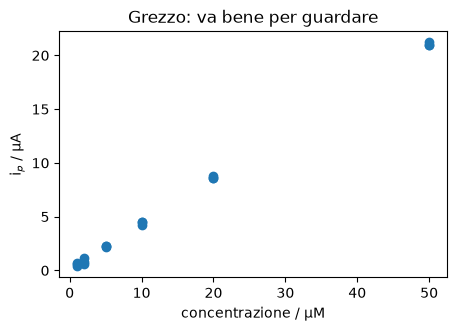

In [3]:
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(tar["conc_uM"], tar["i_uA"], "o")
ax.set_xlabel("concentrazione / µM")
ax.set_ylabel("i$_p$ / µA")
ax.set_title("Grezzo: va bene per guardare")
plt.show()

---
## 2. I tipi fondamentali

| Tipo | Quando | Metodo |
|---|---|---|
| linea | grandezza continua (spettro, voltammogramma, cinetica) | `ax.plot(x, y)` |
| dispersione | coppie di misure (taratura, correlazioni) | `ax.plot(x, y, "o")` o `ax.scatter` |
| barre | confronto fra categorie | `ax.bar(nomi, valori)` |
| istogramma | distribuzione di una variabile | `ax.hist(v, bins=...)` |
| box plot | distribuzione per gruppo | `ax.boxplot([...])` |

Una convenzione che si legge anche senza legenda: i dati sperimentali sono marcatori senza linea,
il modello è una linea senza marcatori.

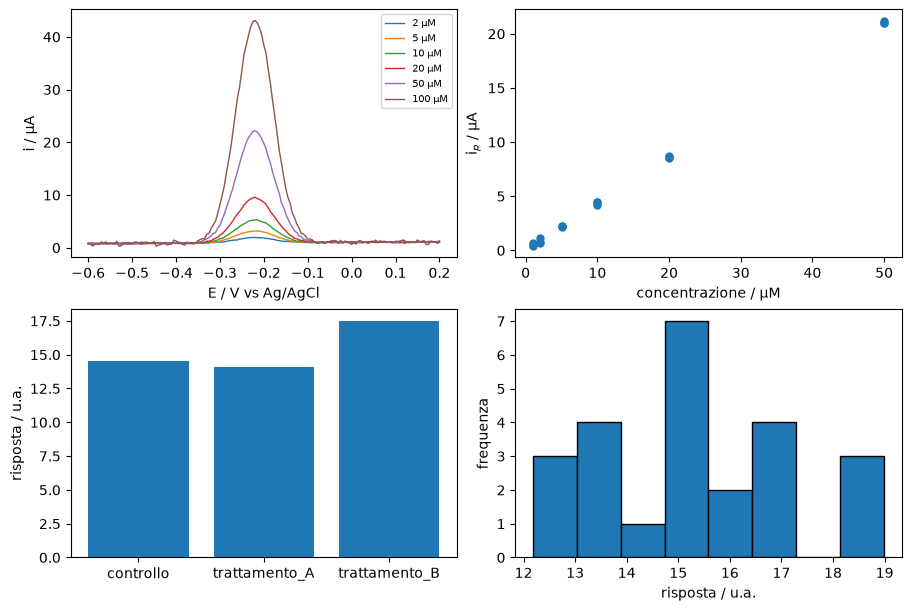

In [4]:
fig, axs = plt.subplots(2, 2, figsize=(9, 6), constrained_layout=True)

# linee: voltammogrammi
for meta, E, i in vamm:
    axs[0, 0].plot(E, i, lw=1, label=f'{meta["Concentrazione nominale (uM)"]} µM')
axs[0, 0].set_xlabel("E / V vs Ag/AgCl"); axs[0, 0].set_ylabel("i / µA"); axs[0, 0].legend(fontsize=7)

# dispersione: taratura
axs[0, 1].plot(tar["conc_uM"], tar["i_uA"], "o", ms=5)
axs[0, 1].set_xlabel("concentrazione / µM"); axs[0, 1].set_ylabel("i$_p$ / µA")

# barre: media per trattamento
medie = grp.groupby("trattamento")["risposta"].mean()
axs[1, 0].bar(medie.index, medie.values)
axs[1, 0].set_ylabel("risposta / u.a."); axs[1, 0].set_ylim(bottom=0)

# istogramma
axs[1, 1].hist(grp["risposta"], bins=8, edgecolor="black")
axs[1, 1].set_xlabel("risposta / u.a."); axs[1, 1].set_ylabel("frequenza")
plt.show()

### Box plot con i punti: con poche repliche è d'obbligo

Con 8 repliche per gruppo, il box plot da solo nasconde più di quanto mostri. Si sovrappongono
i punti con un po' di dispersione orizzontale (*jitter*). Scheda § 5.4.

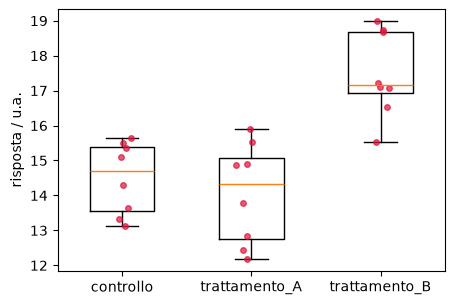

In [5]:
nomi = list(medie.index)
dati_gruppi = [grp.loc[grp["trattamento"] == g, "risposta"].values for g in nomi]
rng = np.random.default_rng(0)

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.boxplot(dati_gruppi, positions=range(3), widths=0.5, showfliers=False)
for k, v in enumerate(dati_gruppi):
    ax.plot(k + rng.normal(0, 0.05, v.size), v, "o", ms=4, alpha=0.7, color="crimson")
ax.set_xticks(range(3), nomi)
ax.set_ylabel("risposta / u.a.")
plt.show()

### Esercizio 5.1: un pannello per tipo (livello 1)

Completate: un box plot con punti della corrente di taratura per livello di concentrazione
(6 gruppi, 3 repliche l'uno). Sull'asse x vanno le concentrazioni.

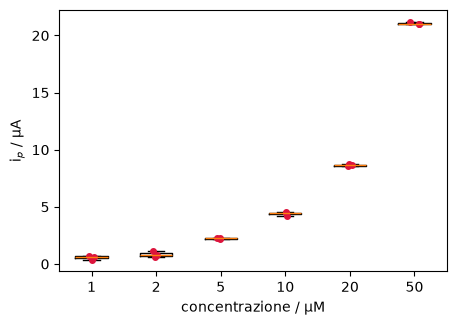

In [6]:
# ESERCIZIO 5.1 (livello 1)
livelli = sorted(tar["conc_uM"].unique())
#> gruppi_tar = [tar.loc[tar["conc_uM"] == c, ____].values for c in livelli]
#> fig, ax = plt.subplots(figsize=(5, 3.4))
#> ax.boxplot(gruppi_tar, positions=range(len(livelli)), widths=0.5, showfliers=False)
#> for k, v in enumerate(gruppi_tar):
#>     ax.plot(k + rng.normal(0, 0.05, v.size), v, "o", ms=4, color="crimson")
#> ax.set_xticks(range(len(livelli)), ____)
#> ax.set_xlabel("concentrazione / µM"); ax.set_ylabel("i$_p$ / µA")
#> plt.show()
# --- SOLUZIONE ---
gruppi_tar = [tar.loc[tar["conc_uM"] == c, "i_uA"].values for c in livelli]
fig, ax = plt.subplots(figsize=(5, 3.4))
ax.boxplot(gruppi_tar, positions=range(len(livelli)), widths=0.5, showfliers=False)
for k, v in enumerate(gruppi_tar):
    ax.plot(k + rng.normal(0, 0.05, v.size), v, "o", ms=4, color="crimson")
ax.set_xticks(range(len(livelli)), livelli)
ax.set_xlabel("concentrazione / µM"); ax.set_ylabel("i$_p$ / µA")
plt.show()

---
## 3. Barre d'errore e rappresentazione dell'incertezza

`ax.errorbar(x, y, yerr=...)`. In `yerr` si passa la grandezza scelta: deviazione standard,
errore standard della media o intervallo di confidenza (scheda § 5.1). Per una curva continua si usa una banda con `fill_between` (§ 5.2).

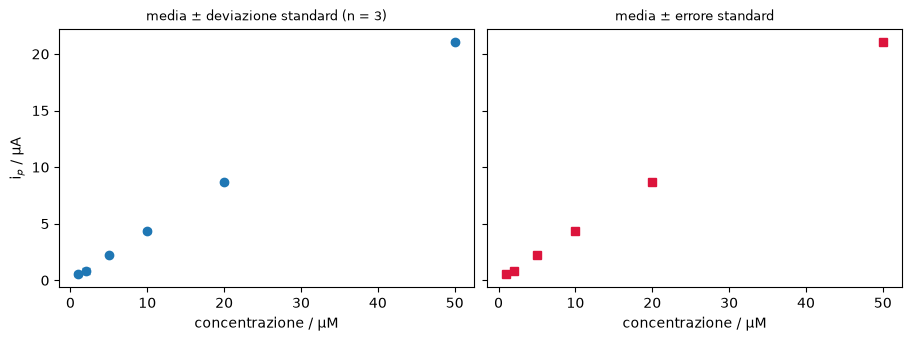

In [7]:
stat = tar.groupby("conc_uM")["i_uA"].agg(["mean", "std", "count"]).reset_index()
stat["sem"] = stat["std"] / np.sqrt(stat["count"])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.3), sharey=True, constrained_layout=True)
a1.errorbar(stat["conc_uM"], stat["mean"], yerr=stat["std"], fmt="o", capsize=3, elinewidth=0.8)
a1.set_title("media ± deviazione standard (n = 3)", fontsize=9)
a2.errorbar(stat["conc_uM"], stat["mean"], yerr=stat["sem"], fmt="s", capsize=3, elinewidth=0.8, color="crimson")
a2.set_title("media ± errore standard", fontsize=9)
for ax in (a1, a2):
    ax.set_xlabel("concentrazione / µM")
a1.set_ylabel("i$_p$ / µA")
plt.show()

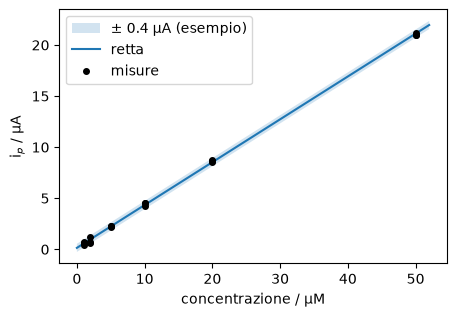

In [8]:
# Banda di incertezza attorno a un modello (retta di taratura; oggi pomeriggio calcoleremo la banda vera)
m, q = np.polyfit(tar["conc_uM"], tar["i_uA"], 1)
x = np.linspace(0, 52, 100)
fig, ax = plt.subplots(figsize=(5, 3.3))
ax.fill_between(x, m * x + q - 0.4, m * x + q + 0.4, alpha=0.2, lw=0, label="± 0.4 µA (esempio)")
ax.plot(x, m * x + q, "-", label="retta")
ax.plot(tar["conc_uM"], tar["i_uA"], "o", ms=4, color="black", label="misure")
ax.set_xlabel("concentrazione / µM"); ax.set_ylabel("i$_p$ / µA"); ax.legend()
plt.show()

---
## 4. Personalizzazione: colori, font, assi, unità, legende

Le cose da fare quasi sempre, e dove trovarle nella scheda:

| Cosa | Come | Scheda |
|---|---|---|
| tratteggi diversi per sopravvivere al bianco e nero | `linestyle="--"` | § 1.2 |
| marcatori vuoti, dimensione | `markerfacecolor="none"`, `ms=` | § 1.3 |
| asse da zero sui grafici a barre | `ax.set_ylim(bottom=0)` | § 2.1 |
| scala logaritmica | `ax.set_xscale("log")` | § 2.4 |
| unità nell'etichetta, non `1e6` sull'asse | `set_ylabel("i / 10$^6$ conteggi")` | § 2.6 |
| equazione e R² nel riquadro | `ax.text(..., transform=ax.transAxes)` | § 3.2 |
| apici, pedici, lettere greche | `r"$\mu$A cm$^{-2}$"` | § 3.5 |
| legenda fissa, senza riquadro | `ax.legend(loc="upper left", frameon=False)` | § 4.1 |
| palette per daltonici (Okabe-Ito) | `rcParams["axes.prop_cycle"]` | § 6.1 |

Impostiamo subito la palette: una volta, in cima al notebook, e non ci si pensa più.

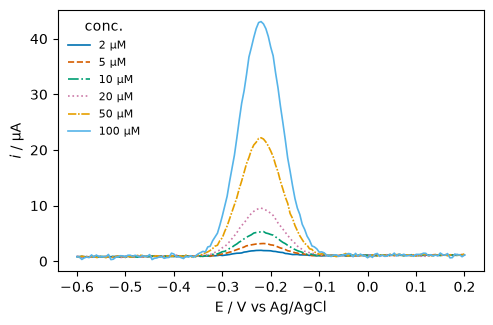

In [9]:
from cycler import cycler
OKABE_ITO = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#F0E442", "#000000"]
mpl.rcParams["axes.prop_cycle"] = cycler(color=OKABE_ITO)

stili = ["-", "--", "-.", ":", (0, (5, 1, 1, 1)), "-"]
fig, ax = plt.subplots(figsize=(5.5, 3.4))
for (meta, E, i), ls in zip(vamm, stili):
    ax.plot(E, i, lw=1.2, linestyle=ls, label=f'{meta["Concentrazione nominale (uM)"]} µM')
ax.set_xlabel("E / V vs Ag/AgCl")
ax.set_ylabel(r"$i$ / µA")
ax.legend(title="conc.", loc="upper left", frameon=False, fontsize=8)
plt.show()

### Esercizio 5.2: da grezza a pubblicabile, primo passo (livello 2)

Tornate alla taratura. Producete una figura con:
1. media ± sd per livello, marcatori vuoti (`fmt="o", markerfacecolor="white"`), `capsize=3`;
2. la retta di regressione (`np.polyfit`) come linea senza marcatori, disegnata sotto i punti (`zorder`);
3. equazione e R² in un riquadro in alto a sinistra (scheda § 3.2, copiate pure);
4. etichette con unità, legenda in basso a destra senza riquadro.

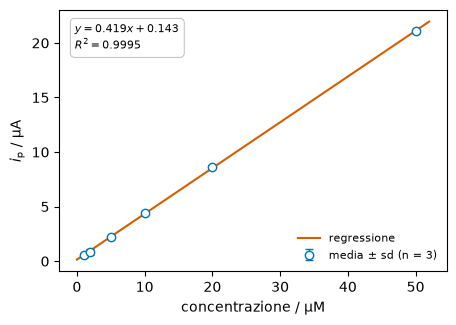

In [10]:
# ESERCIZIO 5.2 (livello 2)
# 1. errorbar su stat (mean, std)
# 2. retta: m, q già calcolati; x da 0 a 52
# 3. R² = 1 - SSres/SStot sui punti singoli (tar)
# 4. testo con transform=ax.transAxes
# --- SOLUZIONE ---
pred = m * tar["conc_uM"] + q
r2 = 1 - np.sum((tar["i_uA"] - pred) ** 2) / np.sum((tar["i_uA"] - tar["i_uA"].mean()) ** 2)

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.plot(x, m * x + q, "-", color="#D55E00", zorder=1, label="regressione")
ax.errorbar(stat["conc_uM"], stat["mean"], yerr=stat["std"], fmt="o", markerfacecolor="white",
            capsize=3, elinewidth=0.8, color="#0072B2", zorder=2, label="media ± sd (n = 3)")
ax.text(0.04, 0.95, f"$y = {m:.3f}x + {q:.3f}$\n$R^2 = {r2:.4f}$", transform=ax.transAxes,
        va="top", ha="left", fontsize=8,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="0.7", linewidth=0.6))
ax.set_xlabel("concentrazione / µM")
ax.set_ylabel(r"$i_\mathrm{p}$ / µA")
ax.legend(loc="lower right", frameon=False, fontsize=8)
plt.show()

---
## 5. Pannelli multipli e assi condivisi

`plt.subplots(righe, colonne, sharex=, sharey=)`. `sharey=True` impone gli stessi limiti
(stessa scala per tutti i pannelli) e toglie le etichette ripetute. `constrained_layout=True` sistema gli
spazi. Le lettere (a) (b) (c) si mettono in ciclo con `transAxes` (scheda § 3.4).

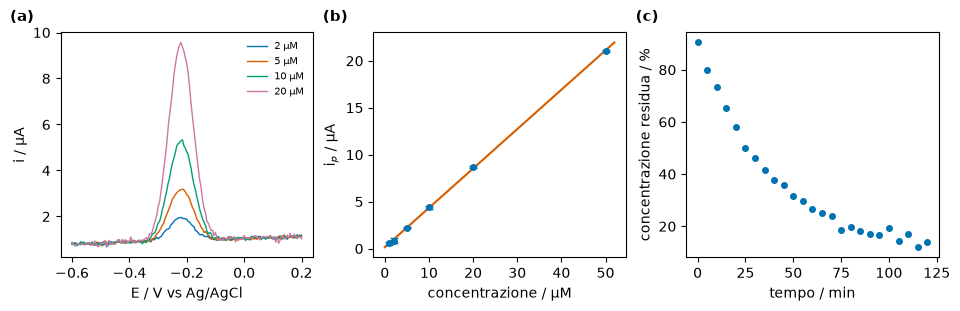

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(9.5, 3), constrained_layout=True)

for (meta, E, i) in vamm[:4]:
    axs[0].plot(E, i, lw=1, label=f'{meta["Concentrazione nominale (uM)"]} µM')
axs[0].set_xlabel("E / V vs Ag/AgCl"); axs[0].set_ylabel("i / µA"); axs[0].legend(fontsize=7, frameon=False)

axs[1].errorbar(stat["conc_uM"], stat["mean"], yerr=stat["std"], fmt="o", capsize=3, ms=4)
axs[1].plot(x, m * x + q, "-", zorder=1)
axs[1].set_xlabel("concentrazione / µM"); axs[1].set_ylabel("i$_p$ / µA")

axs[2].plot(cin["t_min"], cin["conc_residua_%"], "o", ms=4)
axs[2].set_xlabel("tempo / min"); axs[2].set_ylabel("concentrazione residua / %")

for ax, lettera in zip(axs, "abc"):
    ax.text(-0.2, 1.05, f"({lettera})", transform=ax.transAxes, fontsize=11, fontweight="bold")
plt.show()

---
## 6. Standard per la pubblicazione

Le impostazioni che contano per la figura finale vanno fissate quando la si crea, non dopo:

1. **Larghezza fissata** alla colonna della rivista: ~8.5-9 cm (singola), ~17-19 cm (doppia).
   Matplotlib ragiona in pollici: `figsize=(9*CM, 6*CM)` con `CM = 1/2.54`, oppure il
   dizionario `LARGHEZZE` del modulo. Se disegnate a 15 cm e poi rimpicciolite, il testo si
   rimpicciolisce con la figura.
2. Font ≥ 6-8 pt nella figura finale; sans-serif (Arial/Helvetica).
3. Linee ≥ 0.5 pt.
4. Formato vettoriale (PDF, SVG, EPS) quando si può; raster (TIFF) a 300-600 dpi.
5. Font incorporati come TrueType (`pdf.fonttype = 42`): con il default di Matplotlib (Type 3)
   i caratteri diventano disegni e il testo del PDF non si seleziona.
6. Leggibile in bianco e nero e per chi è daltonico: tratteggi e marcatori diversi, non solo colori.
7. `savefig` prima di `plt.show()`, e mai `bbox_inches="tight"` per le figure definitive
   (cambia la larghezza finale).

Il modulo `figure_pubblicazione.py` codifica tutto questo: `stile_rivista()` imposta i
parametri globali, `salva_figura()` esporta con le accortezze (TIFF senza canale alfa,
avviso sull'EPS), `verifica_figura()` controlla dimensioni, font (anche legende e testi) e
spessori delle linee. `stile_rivista()` vale per tutte le figure successive; se volete lo stile
solo per una figura: `with stile_rivista_ctx(): ...` (stesso modulo).

findfont: Font family ['Arial'] not found. Falling back to DejaVu Sans.


ATTENZIONE: 'Arial' non installato. In uso: DejaVuSans
Dimensioni: 3.54 x 2.60 in  (9.0 x 6.6 cm)
  Font: ok (19 testi, minimo 7.0 pt)
  Linee: ok
  Bianco e nero: ok
  Pixel a 600 dpi: 2124 x 1560


salvato: figure/taratura_singola.pdf
salvato: figure/taratura_singola.png


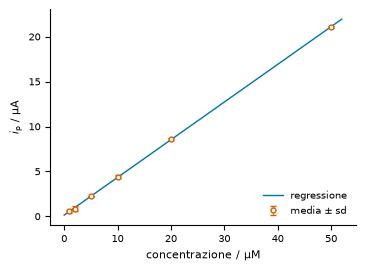

In [12]:
controlla_font("Arial")     # su questo computer probabilmente manca: Matplotlib ripiega su DejaVu Sans
stile_rivista(base_font=8)
# stile_rivista() non tocca i colori: resta attiva la palette Okabe-Ito impostata nella sezione 4

fig, ax = plt.subplots(figsize=(LARGHEZZE["elsevier_singola"], 2.6))
ax.plot(x, m * x + q, "-", zorder=1, label="regressione")
ax.errorbar(stat["conc_uM"], stat["mean"], yerr=stat["std"], fmt="o", ms=3.5, markerfacecolor="white",
            capsize=2, elinewidth=0.6, zorder=2, label="media ± sd")
ax.set_xlabel("concentrazione / µM")
ax.set_ylabel(r"$i_\mathrm{p}$ / µA")
ax.legend(loc="lower right")
verifica_figura(fig)
percorsi = salva_figura(fig, "taratura_singola", formati=("pdf", "png"), dpi=300, cartella="figure")
plt.show()

> Aprite `figure/taratura_singola.pdf`: è largo esattamente 9 cm, e ingrandendo non si sgrana.

### Controllo in scala di grigi

Scheda § 6.3: la funzione `in_grigi(fig)` converte la figura in luminanza. Se due curve
spariscono l'una nell'altra, servono tratteggi o marcatori.

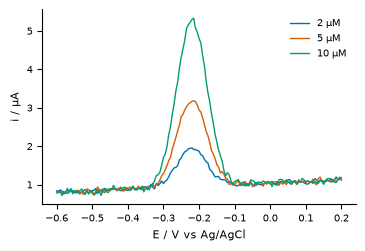

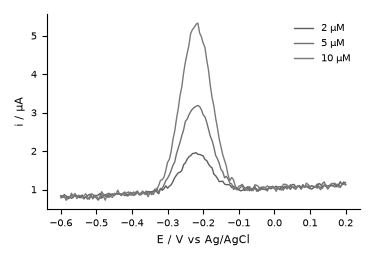

In [13]:
def in_grigi(fig):
    """Restituisce la figura convertita in scala di grigi, per controllo (dalla scheda § 6.3)."""
    fig.canvas.draw()
    rgba = np.asarray(fig.canvas.buffer_rgba(), dtype=float) / 255
    lum = rgba[..., :3] @ np.array([0.2126, 0.7152, 0.0722])
    g = plt.figure(figsize=fig.get_size_inches(), layout="none")
    ax = g.add_axes([0, 0, 1, 1]); ax.axis("off")
    ax.imshow(lum, cmap="gray", vmin=0, vmax=1)
    return g

fig, ax = plt.subplots(figsize=(LARGHEZZE["elsevier_singola"], 2.4))
for (meta, E, i), ls in zip(vamm[:3], ["-", "-", "-"]):     # SOLO colore: cosa succede in b/n?
    ax.plot(E, i, lw=1, linestyle=ls, label=f'{meta["Concentrazione nominale (uM)"]} µM')
ax.set_xlabel("E / V vs Ag/AgCl"); ax.set_ylabel("i / µA"); ax.legend()
g = in_grigi(fig)
plt.show()

### Esercizio 5.3: figura multipannello per la rivista, in PDF vettoriale (livello 3)

Producete la figura definitiva: due pannelli affiancati, larghezza doppia colonna Elsevier
(`LARGHEZZE["elsevier_doppia"]`), altezza 7 cm:
- (a) i voltammogrammi a concentrazione crescente, distinguibili anche in bianco e nero
  (tratteggi diversi *oppure* colori sequenziali `viridis` con barra di colore, scheda § 4.5);
- (b) la retta di taratura con media ± sd, regressione, equazione e R².
- lettere (a), (b); etichette con unità; legende senza riquadro.

Salvate con `salva_figura(fig, "figura_1", formati=("pdf", "tif"), dpi=600)`, poi
`verifica_figura(fig, larghezza_max=7.5)` (il limite predefinito, 7.0 in, è quello ACS; la doppia
colonna Elsevier è 7.48 in). Aprite il PDF e il TIFF e confrontateli.

Dimensioni: 7.48 x 2.76 in  (19.0 x 7.0 cm)
  Font: ok (49 testi, minimo 7.0 pt)
  Linee: ok
  Bianco e nero: ok
  Pixel a 600 dpi: 4488 x 1653


salvato: figure/figura_1.pdf


salvato: figure/figura_1.tif


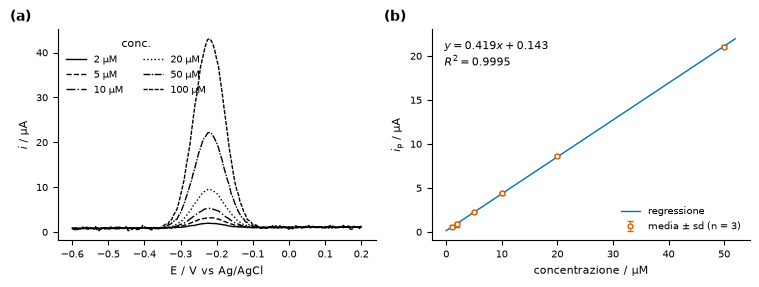

In [14]:
# ESERCIZIO 5.3 (livello 3)
# --- SOLUZIONE ---
fig, (a1, a2) = plt.subplots(1, 2, figsize=(LARGHEZZE["elsevier_doppia"], 7 * CM))

stili = ["-", "--", "-.", ":", (0, (5, 1, 1, 1)), (0, (3, 1))]
for (meta, E, i), ls in zip(vamm, stili):
    a1.plot(E, i, lw=1, linestyle=ls, color="black", label=f'{meta["Concentrazione nominale (uM)"]} µM')
a1.set_xlabel("E / V vs Ag/AgCl")
a1.set_ylabel(r"$i$ / µA")
a1.legend(title="conc.", loc="upper left", ncol=2)

a2.plot(x, m * x + q, "-", zorder=1, label="regressione")
a2.errorbar(stat["conc_uM"], stat["mean"], yerr=stat["std"], fmt="o", ms=3.5, markerfacecolor="white",
            capsize=2, elinewidth=0.6, zorder=2, label="media ± sd (n = 3)")
a2.text(0.04, 0.95, f"$y = {m:.3f}x + {q:.3f}$\n$R^2 = {r2:.4f}$", transform=a2.transAxes, va="top")
a2.set_xlabel("concentrazione / µM")
a2.set_ylabel(r"$i_\mathrm{p}$ / µA")
a2.legend(loc="lower right")

for ax, lettera in zip((a1, a2), "ab"):
    ax.text(-0.15, 1.04, f"({lettera})", transform=ax.transAxes, fontsize=10, fontweight="bold")

verifica_figura(fig, larghezza_max=7.5)     # il default (7.0 in) è il limite ACS; Elsevier accetta 19 cm
salva_figura(fig, "figura_1", formati=("pdf", "tif"), dpi=600, cartella="figure")
plt.show()

> Estensione facoltativa: aggiungete un *inset* nel pannello (b) che ingrandisca la zona
> sotto 5 µM (scheda § 7.3), e un terzo pannello (c) con la cinetica e una banda ± 3 %.

### Confronto finale

Riguardate la vostra figura (a), da soli o con il vicino se vi va. Domande da farsi: si
distinguono le curve in bianco e nero? Il testo è leggibile a 9 cm?
C'è un `1e6` sull'asse? Lo zero delle barre è visibile?

---
## 7. Seaborn: grafici statistici in una riga

> *Facoltativo: si può saltare se si è in ritardo.*

Seaborn è costruito sopra Matplotlib e lavora direttamente con i DataFrame in formato lungo:
gli si passa `data=`, `x=`, `y=`, `hue=` e fa il resto. Ottimo per esplorare; per la figura
finale si torna spesso a Matplotlib puro (o si passa `ax=` a seaborn e si rifinisce).

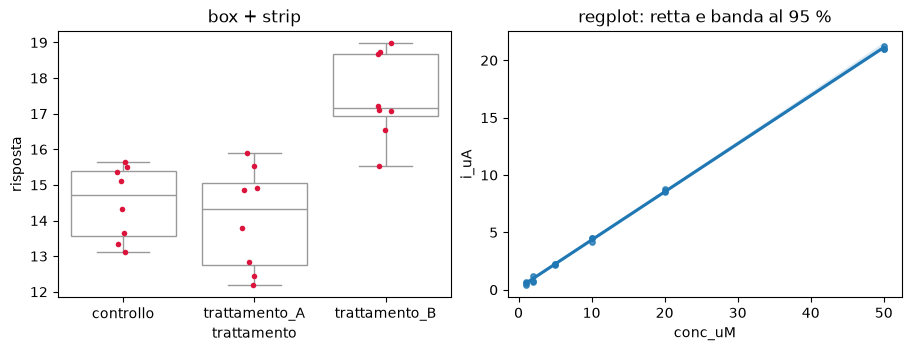

In [15]:
import seaborn as sns
mpl.rcdefaults()                              # torniamo allo stile di default (da schermo)
mpl.rcParams["figure.dpi"] = 100

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.4), constrained_layout=True)
sns.boxplot(data=grp, x="trattamento", y="risposta", ax=a1, color="white", showfliers=False)
sns.stripplot(data=grp, x="trattamento", y="risposta", ax=a1, color="crimson", size=4, jitter=0.1)
a1.set_title("box + strip")

sns.regplot(data=tar, x="conc_uM", y="i_uA", ax=a2, ci=95, scatter_kws={"s": 15})
a2.set_title("regplot: retta e banda al 95 %")
plt.show()

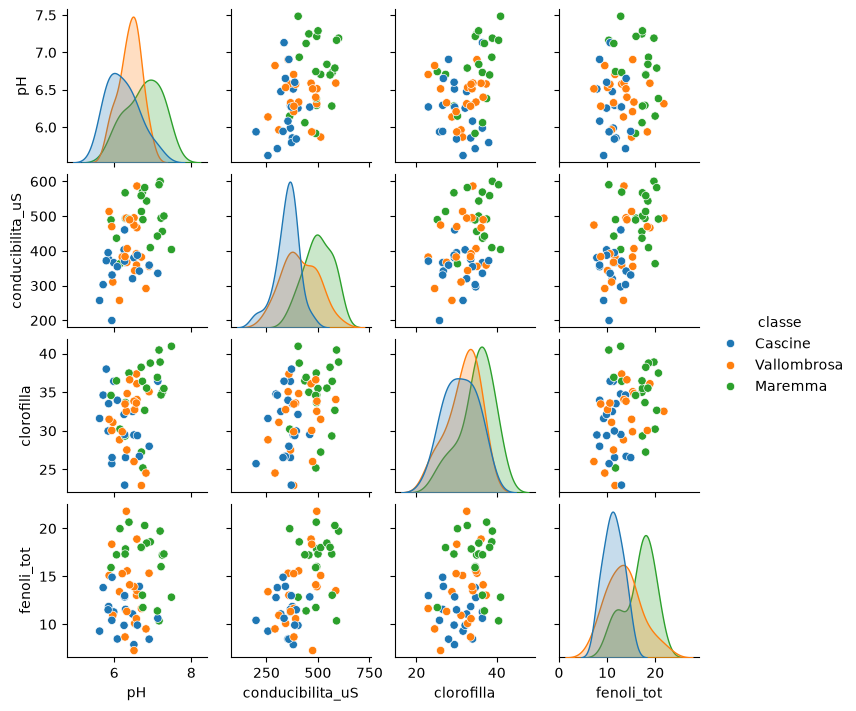

In [16]:
# Matrice di grafici a coppie: la prima cosa da fare su una tabella multivariata (giorno 4)
mat = pd.read_csv(DATI / "sensori_matrice.csv")
g = sns.pairplot(mat[["pH", "conducibilita_uS", "clorofilla", "fenoli_tot", "classe"]], hue="classe", height=1.8)
plt.show()

---
## Riepilogo della mattina

1. `fig, ax = plt.subplots(figsize=...)`, poi solo metodi di `ax`.
2. Dati = marcatori, modello = linea. `yerr` per le barre d'errore, `fill_between` per le bande.
3. Pochi campioni → box plot con i punti.
4. La larghezza si fissa alla creazione; font ≥ 8 pt; PDF vettoriale; leggibile in b/n.
5. `stile_rivista()`, `LARGHEZZE`, `salva_figura()` e `verifica_figura()` fanno il lavoro ripetitivo.
6. La scheda `personalizzazione_grafici.ipynb` è il posto dove cercare quando serve "quel dettaglio".
7. Da R: la cosa più vicina a `ggplot2` è seaborn (`data=`, `x=`, `y=`, `hue=`, formato lungo);
   per la rifinitura da rivista si passa `ax=` a seaborn e si finisce con i metodi di Matplotlib.

Nel pomeriggio: la retta di taratura fatta come si deve (incertezze sui parametri, bande di
confidenza e di predizione), poi fit non lineari, residui e statistica di base.